# Experiment dimensionality reduction

The aim of this document is to test methods to reduce the spatial and temporal dimensions of data.

## References

For further analysis of results related to empirical orthogonal functions I list some practical resources:

- http://www.atmos.colostate.edu/~davet/AT655/notes/Wallace_EOF_tutorial.pdf;
- https://drlee.io/the-ultimate-step-by-step-guide-to-data-mining-with-pca-and-kmeans-83a2bcfdba7d;
- https://scikit-learn.org/stable/modules/clustering.

Another option for isolating components in spatial temporal climate data is Indipendent Component Analysis (ICA), as done in an [article](https://doi.org/10.1175/2008JCLI2571.1) applied to results from EOF analysis.

Some references about mutual information are:

- https://gist.github.com/GaelVaroquaux/ead9898bd3c973c40429#file-mutual_info-py-L8;
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_regression.html;
- https://medium.com/latinxinai/computing-mutual-information-matrix-with-python-6ced9169bcb1.

## Data

I use data obtained for [maximum_consecutive_wet_days](https://xclim.readthedocs.io/en/stable/api_indicators.html#xclim.indicators.atmos.maximum_consecutive_wet_days) indicator for different values of its `thresh` parameters.
The dataset is stored in file `cwd.nc` and it is created originally from ECMWF's ERA5Land dataset, for the time period 1980-2010. Dimension `expver` is present only to [identify consolidated data](https://confluence.ecmwf.int/display/CKB/ERA5-Land%3A+data+documentation#heading-Dataformat).

In [10]:
import xarray

In [11]:
ds = xarray.open_dataset("cwd.nc", decode_timedelta=False)
ds = ds.sel(expver=1).combine_first(ds.sel(expver=5))

## Empirical Orthogonal Function (EOF) analysis

Apply dimensionality reduction using EOF analysis. It is Principal Components Analysis (PCA) where the samples are identified by time and features contain at least the spatial dimensions.

I select `time` and `thresh` as sample dimensions, to reduce over the spatial domain only. Internally, feature dimensions are stacked into a single dimension, ensuring the reference to the original data, and the EOF is applied in parallel to each sample dimension.
The maximum number of modes is given by the rank of the feature matrix, but it is not know a priori. Hence I set a large number of modes (i.e. principal values) and I reduce it to the rank the rank specified in the error message of the Python function I use.

To reduce distortion in data due to latitude, I set the related weighting. The error is neglectible at these latitudes, but I apply the correction anyway to keep the treatment general.

In [12]:
import xeofs

In [13]:
model = xeofs.models.EOF(n_modes=29, compute=False, solver="full", use_coslat=True)
model.fit(ds, dim=("time", "thresh"))

Then I choose a subset of the Principal Components (PCs), i.e. eigenvectors of the covariance matrix.
To do that, I fix a threshold value for the explained variance and choose all the PCs which contribute to the total explained variance up to that value.

In [14]:
import matplotlib.pyplot as plt
import numpy

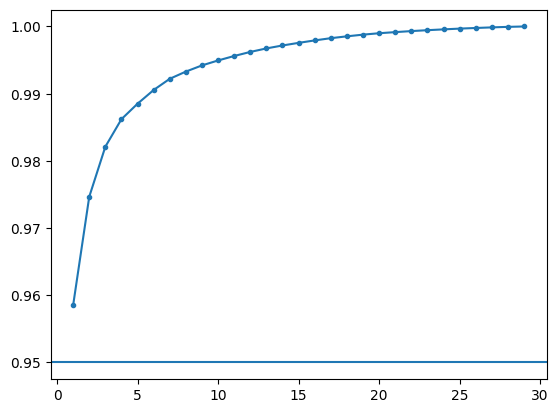

In [15]:
da_evr = model.explained_variance_ratio()
x = da_evr["mode"].values
y = da_evr.values
y_cumsum = numpy.cumsum(y)
evr_threshold = 0.95

plt.plot(x, y_cumsum, '.-')
plt.axhline(y=evr_threshold)

Hence I can consider the first PC only, since its eigenvalue is the largest contribution to the explained variance. This allows to reduce the spatial dimension to one and to keep most of spatial information, supposing it is encoded in the variance of data.

For further insight, I plot the data projected to the first two PCs. In general, the projections of data to the PCs basis (i.e. columns of the matrix resulting from the product of the design matrix with the transformation matrix which diagonalises the covariance matrix) are called scores.

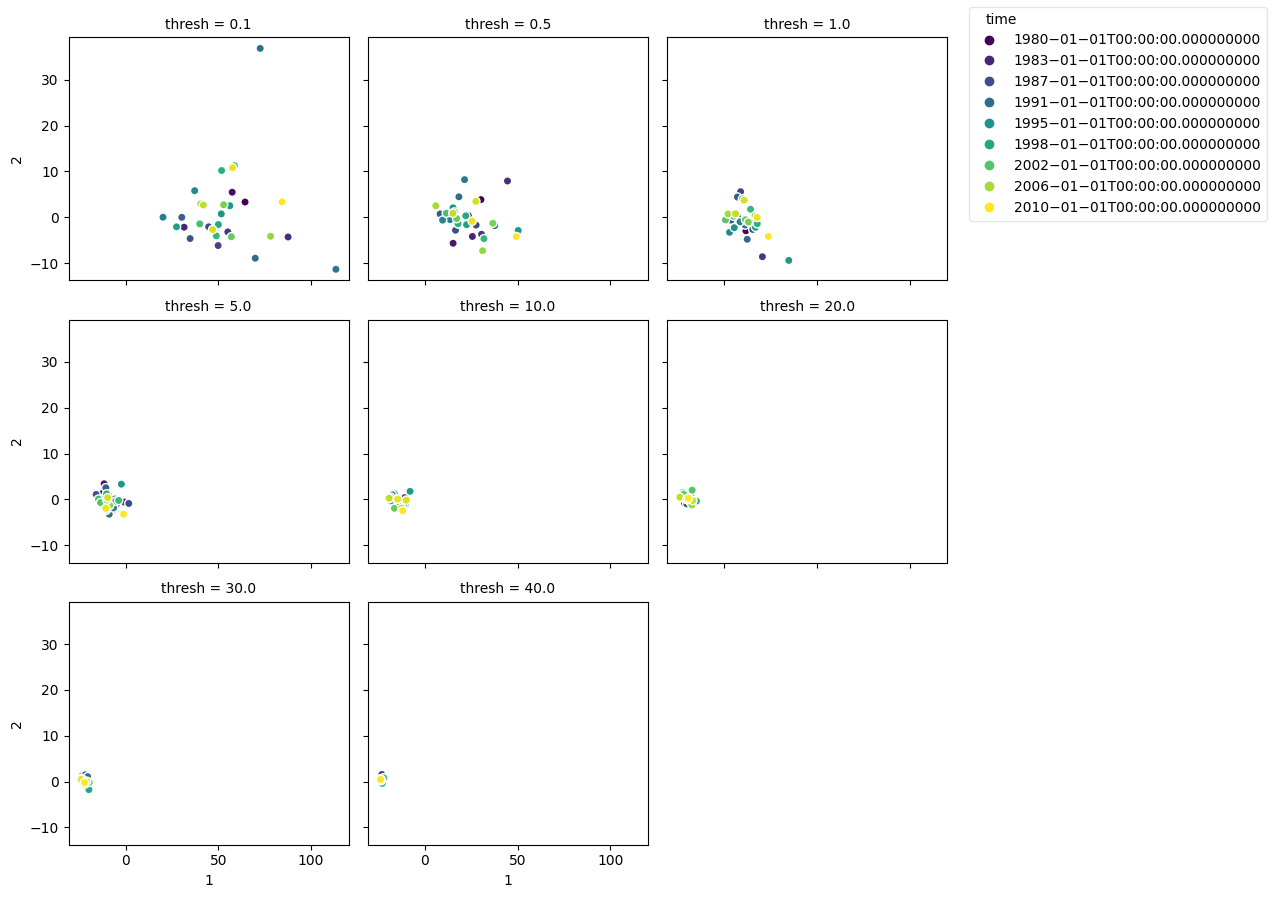

In [16]:
da_scores = model.scores(normalized=False)
ds_scatter = da_scores.to_dataset(dim="mode")
ds_scatter.plot.scatter(x=1, y=2, hue="time", col="thresh", col_wrap=3, add_legend=True, add_colorbar=False)

Low thresholds show high variance within the cluster of scores, even excluding outliers, while increasing the threshold lowers the variance. This behaviour is expected as outcome of the indicator, since it is more likely to have an higher number of consecutive days with low precipitation flux.

Visually there is a significant difference between clusters from threshold values $1.0~\mathrm{mmday}$ and $5.0~\mathrm{mmday}$. This can be seen by plotting a temporal mean and standard deviation of clusters, limited to the first PC for ease.

Text(0, 0.5, 'sample average of scores over time')

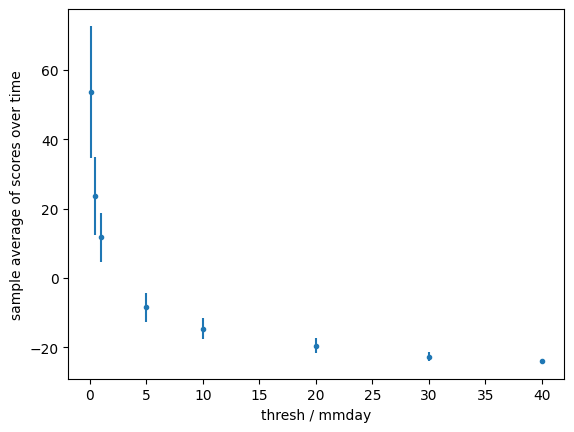

In [17]:
_groupby = da_scores.sel(mode=1).groupby("thresh")
ds_line = xarray.Dataset()
ds_line["mean"] = _groupby.mean(dim="time")
ds_line["std"] = _groupby.std(dim="time")
plt.errorbar(
    x=ds_line["thresh"],
    y=ds_line["mean"],
    yerr=ds_line["std"],
    fmt='.'
)
plt.xlabel(f"thresh / {ds['thresh'].units}")
plt.ylabel("sample average of scores over time")

More points (i.e. more values of the threshold) could suggest different patterns or fitting trends. Also more advanced analysis tools may be more accurate to describe those trends (e.g. K-means clustering to identify)

Notice that to obtain this plot I aggregate data over time dimension with a sample average. This could not be the most suitable technique (e.g. clustering methods may be applied to obtain the centroid of the whole set of scores).

## Mutual information (MI)

EOF (i.e. PCA) works under the assumption that relations between data are linear. Instead, using MI and the mutual information matrix could be a way to address non-linear relations between data.

Dimensionality reduction could be performed by keeping the direction with most mutual information and removing the others, similarly to what is done with EOF.

In [18]:
# Close datasets to release memory.
ds.close()